In [ ]:
import pandas as pd
import numpy as np

In [ ]:
car = pd.read_csv('quikr_car.csv')

In [ ]:
car.head()

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel


In [ ]:
car.shape

(892, 6)

## Quality


In [ ]:
car.info()
# km driven and fuel type has null values

<class 'pandas.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        892 non-null    str  
 1   company     892 non-null    str  
 2   year        892 non-null    str  
 3   Price       892 non-null    str  
 4   kms_driven  840 non-null    str  
 5   fuel_type   837 non-null    str  
dtypes: str(6)
memory usage: 92.3 KB


In [ ]:
car['year'].unique()
# with year data too much garbage and it is in object

<ArrowStringArray>
['2007', '2006', '2018', '2014', '2015', '2012', '2013', '2016', '2010',
 '2017', '2008', '2011', '2019', '2009', '2005', '2000',  '...', '150k',
 'TOUR', '2003', 'r 15', '2004', 'Zest', '/-Rs', 'sale', '1995', 'ara)',
 '2002', 'SELL', '2001', 'tion', 'odel', '2 bs', 'arry',  'Eon', 'o...',
 'ture',  'emi',  'car', 'able',  'no.', 'd...', 'SALE', 'digo', 'sell',
 'd Ex', 'n...', 'e...', 'D...', ', Ac', 'go .', 'k...', 'o c4', 'zire',
 'cent', 'Sumo',  'cab', 't xe',  'EV2', 'r...', 'zest']
Length: 61, dtype: str

In [ ]:
car['name'].unique()

<ArrowStringArray>
[  'Hyundai Santro Xing XO eRLX Euro III',
                'Mahindra Jeep CL550 MDI',
             'Maruti Suzuki Alto 800 Vxi',
 'Hyundai Grand i10 Magna 1.2 Kappa VTVT',
       'Ford EcoSport Titanium 1.5L TDCi',
                              'Ford Figo',
                            'Hyundai Eon',
       'Ford EcoSport Ambiente 1.5L TDCi',
         'Maruti Suzuki Alto K10 VXi AMT',
            'Skoda Fabia Classic 1.2 MPI',
 ...
         'Mercedes Benz C Class 200 K MT',
                            'Skoda Fabia',
  'Maruti Suzuki Alto 800 Select Variant',
             'Maruti Suzuki Ritz VXI ABS',
                       'tata zest 2017 f',
              'Tata Indica V2 DLE BS III',
                                     'Ta',
                    'Tata Zest XM Diesel',
               'Honda Amaze 1.2 E i VTEC',
              'Chevrolet Sail 1.2 LT ABS']
Length: 525, dtype: str

## Quality Of Data
- year has many non-year vals
- year object to int
- price has ask for price written in some places
- price object to int
- kms_driven object to int, remove commas ,remove kms after every value
- kms has nan values
- fuel-type has nan values
- keep first three words of name 

# Cleaning

In [ ]:
backup = car.copy()
# backup so that we dont have to load data again if something goes wrong in pre-processing

In [ ]:
car['year']

0      2007
1      2006
2      2018
3      2014
4      2014
       ... 
887    zest
888    2018
889    2013
890    2014
891    2014
Name: year, Length: 892, dtype: str

In [ ]:
car['year'].str.isnumeric()
# year present in object(string) form checking if str still only contains numeric data

0       True
1       True
2       True
3       True
4       True
       ...  
887    False
888     True
889     True
890     True
891     True
Name: year, Length: 892, dtype: bool

In [ ]:
car = car[car['year'].str.isnumeric()]
car
# only numeric values of year are retained

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
886,Toyota Corolla Altis,Toyota,2009,"3,00,000","1,32,000 kms",Petrol
888,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
889,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
890,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [ ]:
car['year'] = car['year'].astype(int)
car.info()

<class 'pandas.DataFrame'>
Index: 842 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        842 non-null    str  
 1   company     842 non-null    str  
 2   year        842 non-null    int64
 3   Price       842 non-null    str  
 4   kms_driven  840 non-null    str  
 5   fuel_type   837 non-null    str  
dtypes: int64(1), str(5)
memory usage: 91.4 KB


In [ ]:
car = car[car['Price']!="Ask For Price"]
car
# removes ask for price values in price column

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
6,Ford Figo,Ford,2012,"1,75,000","41,000 kms",Diesel
...,...,...,...,...,...,...
886,Toyota Corolla Altis,Toyota,2009,"3,00,000","1,32,000 kms",Petrol
888,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
889,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
890,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [ ]:
# replace commas with empty string - string operation - usefull for removing some characters
# will not run again as already ran and converted it to int

car['Price'] = backup['Price']
car['Price'] = car['Price'].str.replace(',','').astype(int)

In [ ]:
car.info()

<class 'pandas.DataFrame'>
Index: 819 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        819 non-null    str  
 1   company     819 non-null    str  
 2   year        819 non-null    int64
 3   Price       819 non-null    int64
 4   kms_driven  819 non-null    str  
 5   fuel_type   816 non-null    str  
dtypes: int64(2), str(4)
memory usage: 82.4 KB


In [ ]:
car['kms_driven']

0        45,000 kms
1            40 kms
3        28,000 kms
4        36,000 kms
6        41,000 kms
           ...     
886    1,32,000 kms
888      27,000 kms
889      40,000 kms
890          Petrol
891          Petrol
Name: kms_driven, Length: 819, dtype: str

In [ ]:
car['kms_driven'].unique()

<ArrowStringArray>
[  '45,000 kms',       '40 kms',   '28,000 kms',   '36,000 kms',
   '41,000 kms',   '25,000 kms',   '24,530 kms',   '60,000 kms',
   '30,000 kms',   '32,000 kms',
 ...
   '33,400 kms',   '60,123 kms', '1,37,495 kms',   '91,200 kms',
 '1,46,000 kms', '1,00,800 kms',    '2,100 kms',    '2,500 kms',
 '1,32,000 kms',       'Petrol']
Length: 250, dtype: str

In [ ]:
# we can use .str.split(' ').str.get(0) -> it will remove kms return from back
car['kms_driven'] = car['kms_driven'].str.replace('kms','')
car['kms_driven'] = car['kms_driven'].str.replace(',','')
car = car[car['kms_driven']!="Petrol"]
car['kms_driven'] = car['kms_driven'].astype(int)

In [ ]:
car.info()

<class 'pandas.DataFrame'>
Index: 817 entries, 0 to 889
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        817 non-null    str  
 1   company     817 non-null    str  
 2   year        817 non-null    int64
 3   Price       817 non-null    int64
 4   kms_driven  817 non-null    int64
 5   fuel_type   816 non-null    str  
dtypes: int64(3), str(3)
memory usage: 74.2 KB


In [ ]:
car['kms_driven']

0       45000
1          40
3       28000
4       36000
6       41000
        ...  
883     50000
885     30000
886    132000
888     27000
889     40000
Name: kms_driven, Length: 817, dtype: int64

In [ ]:
car.info()

<class 'pandas.DataFrame'>
Index: 817 entries, 0 to 889
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        817 non-null    str  
 1   company     817 non-null    str  
 2   year        817 non-null    int64
 3   Price       817 non-null    int64
 4   kms_driven  817 non-null    int64
 5   fuel_type   816 non-null    str  
dtypes: int64(3), str(3)
memory usage: 74.2 KB


In [ ]:
car['fuel_type'].unique()

<ArrowStringArray>
['Petrol', 'Diesel', nan, 'LPG']
Length: 4, dtype: str

In [ ]:
# ~ means excluding this row take all other rows like !
car = car[~car['fuel_type'].isna()]

In [ ]:
car.info()

<class 'pandas.DataFrame'>
Index: 816 entries, 0 to 889
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        816 non-null    str  
 1   company     816 non-null    str  
 2   year        816 non-null    int64
 3   Price       816 non-null    int64
 4   kms_driven  816 non-null    int64
 5   fuel_type   816 non-null    str  
dtypes: int64(3), str(3)
memory usage: 74.1 KB


In [ ]:
# slice used to take elements present in 0,1,2
car['name'] = backup['name']

In [ ]:
car['name']

0        Hyundai Santro Xing XO eRLX Euro III
1                     Mahindra Jeep CL550 MDI
3      Hyundai Grand i10 Magna 1.2 Kappa VTVT
4            Ford EcoSport Titanium 1.5L TDCi
6                                   Ford Figo
                        ...                  
883                Maruti Suzuki Ritz VXI ABS
885                 Tata Indica V2 DLE BS III
886                      Toyota Corolla Altis
888                       Tata Zest XM Diesel
889                        Mahindra Quanto C8
Name: name, Length: 816, dtype: str

In [ ]:
# I ran a single command multiple times so it kept gettign edited every time 
# hence took it from backup
# therefore always check what changes happening then assign it to original column
car['name'].str.split(' ').str.slice(0,3).str.join(' ')

0         Hyundai Santro Xing
1         Mahindra Jeep CL550
3           Hyundai Grand i10
4      Ford EcoSport Titanium
6                   Ford Figo
                ...          
883        Maruti Suzuki Ritz
885            Tata Indica V2
886      Toyota Corolla Altis
888              Tata Zest XM
889        Mahindra Quanto C8
Name: name, Length: 816, dtype: object

In [ ]:
car['name'] = car['name'].str.split(' ').str.slice(0,3).str.join(' ')

In [ ]:
car.head()

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
3,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
4,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
6,Ford Figo,Ford,2012,175000,41000,Diesel


In [ ]:
# now many inbetweeen index removed so reset them and to not show this index again with the new one use drop
car.reset_index(drop=True)

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
4,Ford Figo,Ford,2012,175000,41000,Diesel
...,...,...,...,...,...,...
811,Maruti Suzuki Ritz,Maruti,2011,270000,50000,Petrol
812,Tata Indica V2,Tata,2009,110000,30000,Diesel
813,Toyota Corolla Altis,Toyota,2009,300000,132000,Petrol
814,Tata Zest XM,Tata,2018,260000,27000,Diesel


In [ ]:
car.shape

(816, 6)

# EDA

In [ ]:
import matplotlib.pyplot as plt

{'whiskers': [<matplotlib.lines.Line2D at 0x345732a50>,
 'caps': [<matplotlib.lines.Line2D at 0x345732cf0>,
 'boxes': [<matplotlib.lines.Line2D at 0x345732900>],
 'medians': [<matplotlib.lines.Line2D at 0x345732f90>],
 'fliers': [<matplotlib.lines.Line2D at 0x3457330e0>],
 'means': []}

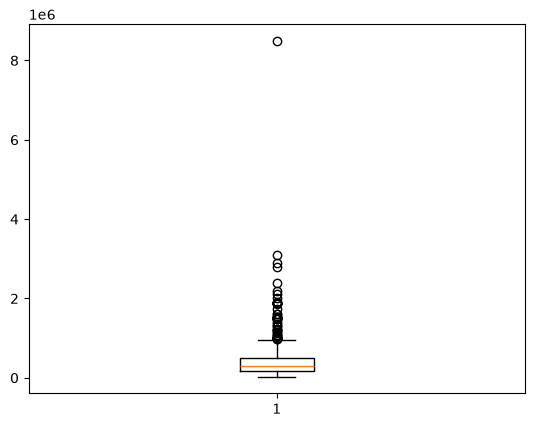

In [ ]:
plt.boxplot(car['Price'])

- see thier is one very extreme outlier so we should remove it 

In [ ]:
car[car['Price']>6e6]

,name,company,year,Price,kms_driven,fuel_type
562,Mahindra XUV500 W6,Mahindra,2014,8500003,45000,Diesel


In [ ]:
car

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
3,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
4,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
6,Ford Figo,Ford,2012,175000,41000,Diesel
...,...,...,...,...,...,...
883,Maruti Suzuki Ritz,Maruti,2011,270000,50000,Petrol
885,Tata Indica V2,Tata,2009,110000,30000,Diesel
886,Toyota Corolla Altis,Toyota,2009,300000,132000,Petrol
888,Tata Zest XM,Tata,2018,260000,27000,Diesel


In [ ]:
car = car[~(car['Price']>6e6)].reset_index(drop = True)

In [ ]:
car

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
4,Ford Figo,Ford,2012,175000,41000,Diesel
...,...,...,...,...,...,...
810,Maruti Suzuki Ritz,Maruti,2011,270000,50000,Petrol
811,Tata Indica V2,Tata,2009,110000,30000,Diesel
812,Toyota Corolla Altis,Toyota,2009,300000,132000,Petrol
813,Tata Zest XM,Tata,2018,260000,27000,Diesel


### data is cleaned store it in some CSV file

In [ ]:
car.to_csv('clean-car.csv')

<Axes: xlabel='fuel_type'>

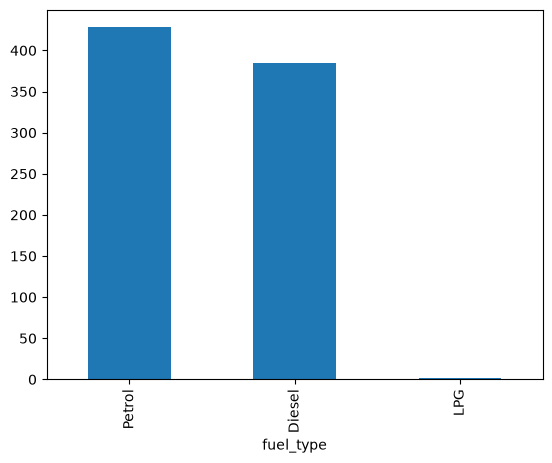

In [ ]:
car['fuel_type'].value_counts().plot(kind='bar')

In [ ]:
(car['fuel_type']=="LPG").unique()

array([False,  True])

# Model 

In [ ]:
car

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
4,Ford Figo,Ford,2012,175000,41000,Diesel
...,...,...,...,...,...,...
810,Maruti Suzuki Ritz,Maruti,2011,270000,50000,Petrol
811,Tata Indica V2,Tata,2009,110000,30000,Diesel
812,Toyota Corolla Altis,Toyota,2009,300000,132000,Petrol
813,Tata Zest XM,Tata,2018,260000,27000,Diesel


In [ ]:
car.info()

<class 'pandas.DataFrame'>
RangeIndex: 815 entries, 0 to 814
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        815 non-null    object
 1   company     815 non-null    str   
 2   year        815 non-null    int64 
 3   Price       815 non-null    int64 
 4   kms_driven  815 non-null    int64 
 5   fuel_type   815 non-null    str   
dtypes: int64(3), object(1), str(2)
memory usage: 48.3+ KB


In [ ]:
X = car.drop(columns='Price')
y = car['Price']

In [ ]:
X

,name,company,year,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,36000,Diesel
4,Ford Figo,Ford,2012,41000,Diesel
...,...,...,...,...,...
810,Maruti Suzuki Ritz,Maruti,2011,50000,Petrol
811,Tata Indica V2,Tata,2009,30000,Diesel
812,Toyota Corolla Altis,Toyota,2009,132000,Petrol
813,Tata Zest XM,Tata,2018,27000,Diesel


In [ ]:
y

0       80000
1      425000
2      325000
3      575000
4      175000
        ...  
810    270000
811    110000
812    300000
813    260000
814    390000
Name: Price, Length: 815, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [ ]:
X_train

,name,company,year,kms_driven,fuel_type
251,Ford Figo Diesel,Ford,2014,50000,Diesel
389,Maruti Suzuki Alto,Maruti,2017,60000,Petrol
81,Honda Brio,Honda,2012,30000,Petrol
67,Chevrolet Spark LS,Chevrolet,2010,41000,Petrol
367,Mahindra Jeep MM,Mahindra,2006,122,Diesel
...,...,...,...,...,...
330,Mahindra Quanto C8,Mahindra,2013,20000,Diesel
404,Chevrolet Spark LS,Chevrolet,2010,23000,Petrol
420,Honda Amaze 1.5,Honda,2016,160000,Diesel
774,Maruti Suzuki Swift,Maruti,2008,58000,Diesel


In [ ]:
X_test

,name,company,year,kms_driven,fuel_type
537,Force Motors One,Force,2013,140000,Diesel
74,Honda Amaze,Honda,2015,22000,Petrol
434,Hyundai Elite i20,Hyundai,2015,30000,Petrol
98,Hyundai i10 Magna,Hyundai,2014,18000,Petrol
551,Maruti Suzuki Ertiga,Maruti,2013,52500,Diesel
...,...,...,...,...,...
765,Hyundai i20 Magna,Hyundai,2011,47000,Petrol
785,Maruti Suzuki Wagon,Maruti,2006,7000,Petrol
793,Honda City 1.5,Honda,2009,55000,Petrol
339,Datsun Redi GO,Datsun,2017,22000,Petrol


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import OneHotEncoder

In [ ]:
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

In [ ]:
ohe = OneHotEncoder()
ohe.fit(X[['name','company','fuel_type']])

,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent

In [ ]:
# apply onehotencoder on mentioned columns 
column_trans = make_column_transformer((OneHotEncoder(categories=ohe.categories_), ['name','company','fuel_type']),remainder='passthrough')

In [ ]:
lr = LinearRegression()

In [ ]:
# creates a pipeline which first apply column transformer and then lr 
pipe = make_pipeline(column_trans, lr)

In [ ]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['name','company','year','kms_driven','fuel_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concaten

In [ ]:
y_pred = pipe.predict(X_test)

In [ ]:
y_pred

array([ 662423.24391913,  316683.40231453,  443936.91668592,
        365308.26513351,  631230.82417127,  211223.22453934,
        582158.06648178,  719897.17793849,  294443.78556237,
        249944.73036787,  441181.31726827, 1030101.04469039,
        426786.70159941,  444718.41306922,  346218.14819743,
        464543.3577622 ,  198410.3758079 ,  289126.69980662,
        285663.97349104,  194824.0065295 ,  504087.35778941,
        628043.32275653,  257342.17368318,  421879.45928646,
        609286.17704714,  643425.53201753,  198610.01931836,
        -14554.41447111,  595740.88737548,  799534.82539963,
        255241.30598845,  446568.94094649,  594591.25332173,
        617575.38754994,  352310.51757577,  222617.29736277,
        280986.35569585,  222194.30276223,  282874.72874029,
        330070.33225384,  770360.74626245,  361919.16092153,
        411622.62415635,  445676.4001407 ,  579607.05214129,
        569333.89811975,  154700.43623631,  417057.98205294,
        559735.52581312,

In [ ]:
r2_score(y_test, y_pred)

0.5738673189431333

In [ ]:
for i in range(10):
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)
    lr = LinearRegression()
    pipe = make_pipeline(column_trans, lr)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    print(r2_score(y_test, y_pred), i)

0.7384019770635485 0
0.6950631134757869 1
0.618574192603805 2
0.7194162461772261 3
0.5842077011221336 4
0.7123136247712051 5
0.48983355049795707 6
0.5202245396831884 7
0.7272631969662992 8
0.6347039253920868 9


### Too much variation in r2 score on different train-test split bcz data is small . select best model based on r2_score

In [ ]:
scores=[]
for i in range(1000):
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=i)
    lr = LinearRegression()
    pipe = make_pipeline(column_trans, lr)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    scores.append(r2_score(y_test, y_pred))

In [ ]:
np.argmax(scores)

np.int64(433)

### max r2 score at 433 value of scores

In [ ]:
scores[np.argmax(scores)]
# gives max r2 score

0.8456642667912282

In [ ]:
# train on the this ranodm state values for max r2 score
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=np.argmax(scores))
lr = LinearRegression()
pipe = make_pipeline(column_trans, lr)
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(r2_score(y_test, y_pred))

0.8456642667912282


In [ ]:
import pickle

In [ ]:
pickle.dump(pipe, open('LinearRegressionModel.pkl','wb'))

In [ ]:
pipe.predict(pd.DataFrame([['Maruti Suzuki Swift', 'Maruti', 2019, 100, 'Petrol']], columns=['name','company','year','kms_driven', 'fuel_type']))
# predicted value for this values of input

array([459062.10569844])